# **Aula 06 - Imputação e Normalização de Dados**

## 1. Preparando a base

In [38]:
# Importa as bibliotecas e define o tema dos gráficos
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from google.colab import files
uploaded = files.upload()

from sklearn.preprocessing import (
    MinMaxScaler,
    PowerTransformer,
    RobustScaler,
    StandardScaler,
)

sns.set_theme(style="whitegrid", palette="colorblind")

Saving imoveis_sao_paulo.csv to imoveis_sao_paulo (1).csv


Este bloco prepara o ambiente importando as bibliotecas que vão ser usadas ao longo do notebook e define a aparência dos gráficos.

* **pathlib (`Path`)**: representa o caminho do arquivo da base de forma que funcione em qualquer sistema operacional.
* **NumPy**: realiza cálculos numéricos com vetores, como `np.log`, `np.log1p` e `np.where`.
* **pandas**: trabalha com tabelas. Lê o CSV, renomeia colunas, remove duplicatas, agrupa os dados e preenche lacunas.
* **Matplotlib**: cria as figuras e os painéis dos gráficos.
* **Seaborn**: construído sobre o Matplotlib, produz gráficos estatísticos, como histogramas e gráficos de barras.
* **SciPy (`stats`)**: fornece funções estatísticas, como a assimetria (`skew`) e as transformações Box-Cox e Yeo-Johnson.
* **scikit-learn**: fornece os escaladores `StandardScaler`, `RobustScaler` e `MinMaxScaler` e o `PowerTransformer`, usados nas seções de escalonamento e transformação.

Por fim, `sns.set_theme` define um padrão visual para todos os gráficos do notebook: fundo branco com grade (`whitegrid`), que facilita a leitura dos valores, e uma paleta de cores acessível (`colorblind`).

In [39]:
# Novos nomes para as colunas com espaços e símbolos
column_names = {
    "parking spaces": "parking_spaces",
    "hoa (R$)": "hoa",
    "rent amount (R$)": "rent_amount",
    "property tax (R$)": "property_tax",
    "total (R$)": "total",
}

# Carrega a base, remove duplicatas e identifica o tipo de imóvel
imoveis = (
    pd.read_csv("imoveis_sao_paulo.csv")
    .rename(columns=column_names)
    .drop_duplicates()
    .reset_index(drop=True)
    .assign(
        property_type=lambda df: np.where(
            df["floor"].isna(),
            "casa",
            "apartamento",
        )
    )
)

O dicionário `column_names` define os novos nomes para as colunas que tem espaços e símbolos, e que passa a seguir o padrão snake_case. Esse padrão facilita o acesso às colunas no código.

Em seguida, a base é carregada e passa por uma sequência de ajustes:

1. **Renomeação das colunas**, usando o dicionário anteriormente.
2. **Remoção de linhas duplicadas**, para que um mesmo anúncio não seja contado mais de uma vez nas estatísticas e nos gráficos.
3. **Renumeração do índice**, já que a remoção de duplicatas deixa lacunas na numeração das linhas.
4. **Criação da coluna `property_type`**: imóveis sem andar informado (`floor` vazio) são classificados como casa, e os demais como apartamento.

Com isso podemos pensar também que um valor ausente pode ter um significado importante para a analie dos dados e modificar uma conclusão, visto que a falta de andar não é um erro, e sim uma característica das casas. Ao registrar isso em uma nova coluna, essa informação deixa de estar escondida e pode ser usada nas análises seguintes.

### 1.1 Os três problemas da aula

Foi utilizado o conjunto de dados da aula para exemplificar os problemas.

* **Valores ausentes:** Se não forem tratadas, as lacunas causam problemas para analisar o conjunto, pois podem ser selecionados subconjuntos diferentes ao descartar as linhas com valores ausentes.

* **Escalas incompatíveis:** Na base de dados utilizada na aula temos registros dos aluguéis de imóveis, com dados como quantidade de quartos em unidade, área do imóvel em metro quadrado e valor de aluguel em reais, ou seja, as variáveis estão em diferentes grandezas, o que pode dificultar a execução de alguns algoritmos. Nos gráficos, há predominância de um fator que parece ser o mais importante, que no caso seria o aluguel, mas isso acontece apenas por causa da unidade.

* **Cauda longa:** A maioria dos aluguéis fica abaixo de R$ 5.100, mas poucos imóveis muito caros chegam a uma diferença gritante. Essa assimetria pode causar problemas nos resultados das análises, pois a média vai ser puxada por esses outliers e gerar uma representação errada da realidade.

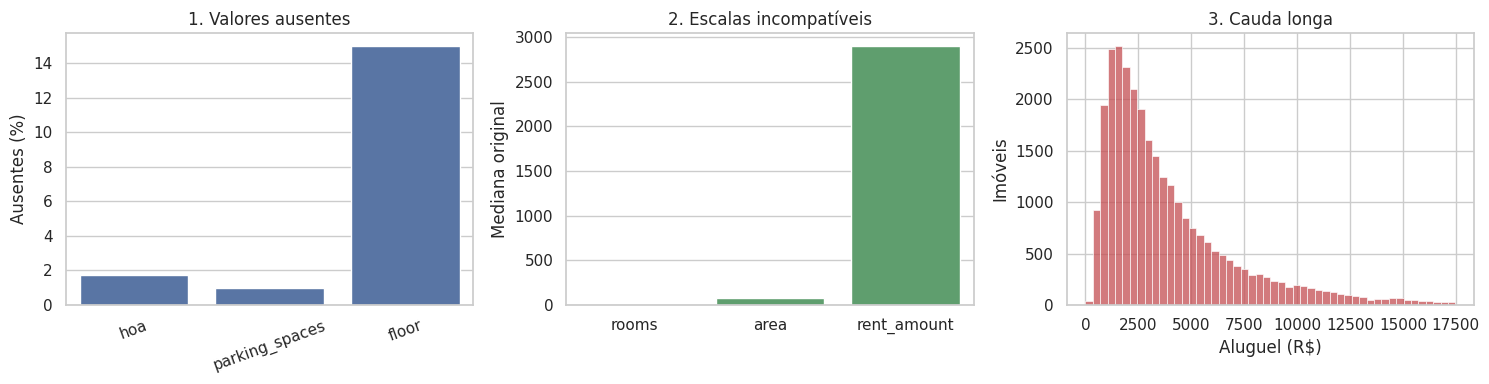

In [40]:
# Valores exibidos em cada painel da figura
missing = (
    imoveis[["hoa", "parking_spaces", "floor"]]
    .isna()
    .mean()
    .mul(100)
)

scales = (
    imoveis[["rooms", "area", "rent_amount"]]
    .median()
)

limit = imoveis["rent_amount"].quantile(.99)

# Figura-resumo com os três problemas da aula
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.barplot(
    x=missing.index,
    y=missing.values,
    ax=axes[0],
    color="#4C72B0",
)
axes[0].set(
    title="1. Valores ausentes",
    ylabel="Ausentes (%)",
    xlabel="",
)
axes[0].tick_params(axis="x", rotation=20)

sns.barplot(
    x=scales.index,
    y=scales.values,
    ax=axes[1],
    color="#55A868",
)
axes[1].set(
    title="2. Escalas incompatíveis",
    ylabel="Mediana original",
    xlabel="",
)

sns.histplot(
    imoveis["rent_amount"],
    bins=50,
    binrange=(0, limit),
    ax=axes[2],
    color="#C44E52",
)
axes[2].set(
    title="3. Cauda longa",
    xlabel="Aluguel (R$)",
    ylabel="Imóveis",
)

plt.tight_layout()
plt.show()

* **Valores ausentes:** Em `hoa` (cerca de 1,7%) e `parking_spaces` (cerca de 1%), as poucas lacunas sugerem falhas pontuais de cadastro, que podem ser tratadas por imputação sem grande impacto na base. Em `floor` (cerca de 15%), a proporção é alta demais para ser acaso, há um motivo para a falta dessa informação. Por isso, antes de preencher qualquer valor, é preciso investigar a causa, para não criaria um dado falso.

* **Escalas incompatíveis:** o fato de o aluguel dominar o gráfico não significa que ele seja a variável mais importante, e sim que está medido em uma unidade com números maiores. Uma diferença de 1 quarto entre dois imóveis é relevante, mas, numericamente, vale muito menos que uma diferença de valor no alguel. Se as variáveis forem usadas assim em um algoritmo baseado em distância, o resultado dependerá quase só do aluguel. Por isso, elas precisam ser colocadas em escalas comparáveis antes da modelagem.

* **Cauda longa:** a concentração de imóveis entre R$ 1.000 e R$ 5.000, seguida de uma cauda que se estende para a direita, mostra que o mercado é formado por muitos imóveis de aluguel moderado e poucos imóveis muito caros. Esses poucos imóveis puxam a média para cima, então a média deixa de representar o aluguel real, e a mediana se torna uma medida mais adequada. A cauda também faz com que os imóveis caros tenham peso exagerado em análises e modelos, o que indica a necessidade de uma transformação para reduzir a assimetria.

Em resumo, os três gráficos mostram que a base precisa de tratamento antes de ser analisada.

## 2. Ausência estrutural

In [41]:
# Número de imóveis e proporção sem andar, por tipo
(
    imoveis
    .groupby("property_type")
    .agg(
        imoveis=("property_type", "size"),
        proporcao_sem_andar=(
            "floor",
            lambda x: (
                x
                .isna()
                .mean()
            ),
        ),
    )
)

,imoveis,proporcao_sem_andar
property_type,,
apartamento,25024,0.0
casa,4415,1.0


O código separa os imóveis por tipo e calcula, em cada grupo, a quantidade de imóveis e a proporção sem andar informado.

O resultado mostra que todos os 25.024 apartamentos têm andar informado, enquanto todas as 4.415 casas estão sem andar. As casas representam cerca de 15% da base, exatamente a proporção de lacunas em `floor` vista no gráfico de valores ausentes. Ou seja, todas as lacunas dessa coluna vêm das casas.

Isso indica uma **ausência estrutural**: o andar descreve a posição de uma unidade dentro de um prédio e, por isso, não se aplica a casas. Não houve erro de cadastro, a informação simplesmente não existe para esse tipo de imóvel.

Por esse motivo, `floor` **não deve ser imputada**. Preencher o andar de uma casa com a média ou a mediana dos apartamentos criaria um valor sem significado, e um modelo poderia aprender um padrão falso a partir dele. A solução adotada foi registrar essa característica na coluna `property_type`, que torna explícita a informação que antes estava escondida na lacuna.

## 3. Imputação: o impacto das alternativas

In [42]:
# Função de apagamento e base-gabarito
rng = np.random.default_rng(42)

def erase_at_random(values, share):
    return values.mask(rng.random(len(values)) < share)

imoveis_true = (
    imoveis
    .dropna(subset=["hoa", "parking_spaces"])
    .reset_index(drop=True)
)

Para avaliar uma imputação, seria preciso comparar o valor estimado com o valor verdadeiro em uma lacuna real, porém, o valor verdadeiro é desconhecido, e não há como medir o erro. A solução é montar um experimento que parte de dados completos, apagar alguns valores de propósito, após isso irá imputá-los e comparar as estimativas com os valores originais.

* **O sorteador `rng`:** é um gerador de números aleatórios com semente fixa. A semente faz com que a sequência de sorteios seja sempre a mesma, então quem executar o notebook vai apagar exatamente os mesmos valores e obter os mesmos resultados, para que possa torna o experimento reproduzível.

* **A função `erase_at_random`:** recebe uma coluna e a proporção de valores a apagar. Ela sorteia um número entre 0 e 1 para cada linha e, quando o sorteio fica abaixo de share, troca o valor por NaN com o método. Por exemplo, com share = 0.10, cerca de 10% dos valores são apagados. Como todas as linhas têm a mesma chance de serem escolhidas, as lacunas são totalmente aleatórias.

* **A base-gabarito `imoveis_true`:** contém apenas os imóveis com `hoa` e `parking_spaces` preenchidos, pois os imóveis que já tinham lacunas reais nessas colunas foram removidos. Ela guarda os valores verdadeiros de referência: como não tem lacunas próprias, toda posição apagada depois terá um valor original para comparação. O `reset_index` renumera as linhas, que ficaram com buracos após a remoção.

In [43]:
# Apaga valores em três colunas de tipos diferentes
imoveis_missing = (
    imoveis_true
    .assign(
        rooms=lambda df: erase_at_random(df["rooms"], .10),
        rent_amount=lambda df: erase_at_random(df["rent_amount"], .15),
        furniture=lambda df: erase_at_random(df["furniture"], .08),
    )
)

São criadas lacunas em três colunas de tipos diferentes, porque cada tipo de variável exige uma estratégia de imputação diferente:

* `rooms` é uma variável discreta, que só assume valores inteiros, com 10% apagados;
* `rent_amount` é uma variável contínua e assimétrica, com 15% apagados;
* `furniture` é uma variável categórica, com as categorias mobiliado e não mobiliado, com 8% apagados.

A base `imoveis_true` continua intacta, e as lacunas ficam apenas na cópia `imoveis_missing`. Assim, o valor original de cada posição apagada continua disponível para comparação.

In [44]:
# Quantidade e proporção de valores apagados por coluna
(
    imoveis_missing[["rooms", "rent_amount", "furniture"]]
    .isna()
    .sum()
    .to_frame("ausentes")
    .assign(
        proporcao=lambda x: (
            x.ausentes / len(imoveis_missing)
        ).round(3)
    )
)

,ausentes,proporcao
rooms,2783,0.097
rent_amount,4308,0.150
furniture,2254,0.079


Foram apagados 2.783 valores de `rooms`, 4.308 de `rent_amount` e 2.254 de `furniture`. As proporções obtidas (9,7%, 15,0% e 7,9%) ficam muito próximas das proporções definidas em código.

Elas não são exatamente iguais porque cada linha passa por um sorteio independente, em vez de se escolher um número fixo de linhas. Essa pequena variação é esperada e confirma que o apagamento funcionou como planejado.

**Por que o mecanismo de ausência importa?**

O motivo pelo qual um valor está ausente afeta a qualidade da imputação. Existem três mecanismos:

* **MCAR (ausência completamente aleatória):** a chance de faltar não depende de nada. Exemplo: um erro aleatório de sistema apaga o aluguel de alguns imóveis. Nesse caso, os dados observados representam bem a base, e a imputação não gera viés.
* **MAR (ausência aleatória condicionada):** a chance de faltar depende de outra variável observada. Exemplo: anúncios de um certo tier deixam de informar as vagas com mais frequência. Nesse caso, imputar por grupo, usando a variável que explica a ausência, reduz o viés.
* **MNAR (ausência não aleatória):** a chance de faltar depende do próprio valor ausente. Exemplo: os donos de imóveis muito caros preferem não informar o aluguel. Nesse caso, nenhuma estatística dos valores observados recupera o valor real, e a imputação tende a subestimar os aluguéis.

O experimento desta seção apaga valores ao acaso, ou seja, simula o caso MCAR, que é o mais favorável. Por isso, os erros medidos aqui mostram o desempenho das estratégias no melhor cenário. Na base real, se a ausência seguir outro mecanismo, os erros podem ser maiores.

### 3.1 Média, mediana e mediana agrupada

In [45]:
# Constantes para a imputação simples
rent_mean = (
    imoveis_missing.rent_amount
    .mean()
)

rent_median = (
    imoveis_missing.rent_amount
    .median()
)

print(f"Média:   R$ {rent_mean:,.2f}")
print(f"Mediana: R$ {rent_median:,.2f}")

Média:   R$ 4,054.54
Mediana: R$ 2,901.58


Este bloco calcula as duas constantes usadas na imputação simples do aluguel: a média e a mediana. Elas são calculadas apenas com os valores observados, pois o pandas ignora os valores ausentes. Na imputação simples, todas as lacunas recebem o mesmo valor.

A média fica acima da mediana, isso acontece por causa da cauda longa, a média usa o valor de todos os aluguéis e, por isso, é puxada para cima pelos poucos imóveis muito caros. A mediana depende apenas da posição central dos dados e não é afetada por esses valores extremos.

Na prática, isso significa que a média representa mal o imóvel típico desta base. Ao preencher as lacunas com ela, a maioria dos imóveis receberia um aluguel acima do real. Por isso, espera-se que a mediana produza estimativas mais próximas dos valores verdadeiros, o que será verificado com o cálculo do erro.

**OBS:** Adicionei o print dos resultados para verificar a diferença

In [46]:
# Imputação pela mediana de cada tier
rent_group = (
    imoveis_missing
    .groupby("tier")
    .rent_amount
    .transform(lambda x: x.fillna(x.median()))
    .fillna(rent_median)
)

In [47]:
imoveis_missing.groupby("tier").rent_amount.median()

,rent_amount
tier,
affordable,1350.0
luxury,7350.0
mid,2490.0
premium,4570.0


Este bloco preenche as lacunas do aluguel com a mediana do tier de cada imóvel, em vez de usar uma única mediana para toda a base.

* `groupby("tier")` separa os imóveis por tier
* `transform` calcula a mediana do aluguel dentro de cada tier e preenche as lacunas daquele grupo com ela. O `transform` devolve uma coluna do mesmo tamanho da original, com cada valor na sua posição
* `fillna(rent_median)` funciona como reserva: se algum tier não tiver nenhum aluguel observado, sua mediana não pode ser calculada, e as lacunas desse grupo recebem a mediana global.

A vantagem dessa estratégia é usar uma informação adicional sobre o imóvel. O aluguel típico varia bastante de um tier para outro, e uma mediana única ignora essa diferença: um imóvel de padrão alto receberia um aluguel abaixo do real, e um de padrão baixo, um aluguel acima. Com a mediana por tier, cada lacuna recebe um valor mais próximo dos imóveis semelhantes a ela.

Por isso, espera-se que essa estratégia tenha um erro menor que a média e a mediana globais.

In [48]:
# Versões do aluguel a comparar
rent_versions = {
    "Original": imoveis_true.rent_amount,
    "Com lacunas": imoveis_missing.rent_amount,
    "Média": imoveis_missing.rent_amount.fillna(rent_mean),
    "Mediana": imoveis_missing.rent_amount.fillna(rent_median),
    "Mediana por tier": rent_group,
}

Este bloco reúne cinco versões da coluna de aluguel para que possam ser comparadas

* **Original:** os valores verdadeiros, do gabarito
* **Com lacunas:** a coluna após o apagamento, com 15% dos valores ausentes
* **Média:** as lacunas preenchidas com a média dos aluguéis observados
* **Mediana:** as lacunas preenchidas com a mediana dos aluguéis observados
* **Mediana por tier:** as lacunas preenchidas com a mediana do tier de cada imóvel.

Organizar as versões dessa forma permite gerar todos os gráficos com um único laço no bloco seguinte, em vez de repetir o código cinco vezes.

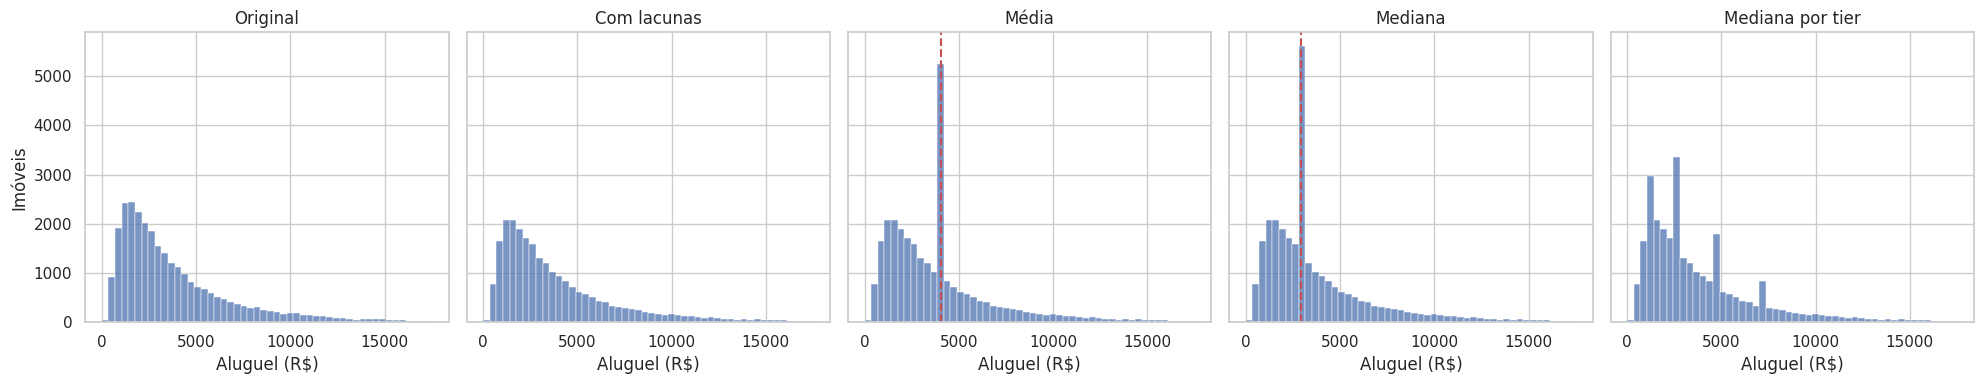

In [49]:
# Histograma de cada versão do aluguel
fig, axes = plt.subplots(1, 5, figsize=(20, 4), sharey=True)

limit = imoveis_true.rent_amount.quantile(.99)

for ax, (label, values) in zip(axes, rent_versions.items()):
    sns.histplot(
        values.dropna(),
        bins=50,
        binrange=(0, limit),
        ax=ax,
        color="#4C72B0",
    )
    ax.set(
        title=label,
        xlabel="Aluguel (R$)",
        ylabel="Imóveis",
    )
    if label == "Média":
        ax.axvline(
            rent_mean,
            color="#C44E52",
            linestyle="--",
        )
    if label == "Mediana":
        ax.axvline(
            rent_median,
            color="#C44E52",
            linestyle="--",
        )

plt.tight_layout()
plt.show()

Os cinco histogramas mostram como cada estratégia altera a distribuição do aluguel. Todos usam a mesma escala vertical e o mesmo recorte para que possam ser comparados diretamente. Nos painéis da média e da mediana, a linha tracejada marca o valor usado para preencher as lacunas.

O painel **Com lacunas** tem a mesma forma do **Original**, mas com barras um pouco mais baixas, já que 15% dos valores foram apagados de forma aleatória.

Nos painéis **Média** e **Mediana**, aparece um **pico artificial** exatamente na linha tracejada. Isso acontece porque todas as cerca de 4.300 lacunas recebem o mesmo valor e se acumulam em uma única barra. A distribuição deixa de refletir os dados reais, pois surge uma concentração de imóveis com um aluguel que não corresponde à realidade.

No painel **Mediana por tier**, as lacunas são distribuídas entre vários valores, um por tier. Os picos ainda existem, mas são menores e ficam espalhados, de modo que o histograma fica mais parecido com o original.

Os histogramas mostram o efeito de cada estratégia sobre a **forma** da distribuição.

###   *3.1.1 Erro absoluto médio (MAE)*

In [50]:
# Posições apagadas e seus valores verdadeiros
rent_missing = imoveis_missing.rent_amount.isna()

truth = imoveis_true.loc[rent_missing, "rent_amount"]

Para medir o erro das imputações, é preciso comparar cada valor imputado com o valor verdadeiro na mesma posição.

* `rent_missing` marca com `True` as linhas em que o aluguel foi apagado e com `False` as demais
* `truth` usa essa marcação para buscar no gabarito o aluguel verdadeiro apenas dessas linhas.

O cálculo do erro considera somente as posições apagadas, pois nas posições que não foram apagadas, o valor não foi alterado pela imputação e o erro é zero e se fosse considerado afetaria o resultado real.

In [51]:
# MAE de cada estratégia, apenas nas posições imputadas
(
    pd.Series(
        {
            "Média": (
                (truth - rent_mean)
                .abs()
                .mean()
            ),
            "Mediana": (
                (truth - rent_median)
                .abs()
                .mean()
            ),
            "Mediana por tier": (
                (truth - rent_group[rent_missing])
                .abs()
                .mean()
            ),
        },
        name="MAE (R$)",
    )
    .round(2)
    .to_frame()
)

,MAE (R$)
Média,2505.30
Mediana,2313.52
Mediana por tier,1820.84


O erro absoluto médio (MAE) mede, em média, o quanto cada imputação se afastou do valor verdadeiro. Para cada imóvel, calcula-se a diferença entre o aluguel verdadeiro e o imputado, o valor absoluto impede que valores negativos se cancele com os positivos, e a média resume o erro de todas as lacunas. Como o MAE está na mesma unidade da variável, pode ser lido diretamente em reais.

Com o resultado podemos chegar a algumas informações como:

* **A média teve o maior erro**: em média, errou o aluguel em cerca de R$ 2.500. Como ela é puxada para cima pelos aluguéis muito altos, superestima o aluguel da maioria dos imóveis.
* **A mediana teve erro controlado.** Além de não ser afetada pela cauda longa, a mediana é, por definição, o valor que minimiza a soma dos erros absolutos.
* **A mediana por tier teve o menor erro**, ela usa uma informação adicional, o padrão do imóvel, e com isso aproxima cada estimativa dos imóveis semelhantes.

Mesmo a melhor estratégia ainda erra, o que mostra que a imputação apenas aproxima a informação perdida, mas não à recupera.

### 3.2 Moda e variáveis discretas

In [52]:
# Categoria mais frequente de furniture
furniture_mode = (
    imoveis_missing.furniture
    .mode()
    .iloc[0]
)

furniture_mode

'not furnished'

A coluna `furniture` é uma variável categórica, com duas categorias: mobiliado e não mobiliado, em variáveis desse tipo, média e mediana não podem ser usadas, pois não existe uma conta possível entre os valores, então a imputação usa a **moda**.

O código calcula a moda com `.mode()` para encontrar a categoria mais frequente e `.iloc[0]` seleciona o primeiro item dessa lista, que orresponde ao mais frequente com os dados utilizados.

O resultado é `'not furnished'`: a maioria dos imóveis da base não é mobiliada, isso desconsiderando os campos não informados.

In [53]:
# Contagem das categorias antes e depois da imputação
(
    pd.concat(
        {
            "Antes": imoveis_missing.furniture.value_counts(dropna=False),
            "Depois da moda": (
                imoveis_missing.furniture
                .fillna(furniture_mode)
                .value_counts()
            ),
        },
        axis=1,
    )
    .fillna(0)
)

,Antes,Depois da moda
furniture,,
not furnished,17265,19519.0
furnished,9122,9122.0
NaN,2254,0.0


A tabela compara a quantidade de imóveis em cada categoria antes e depois da imputação pela moda, contando também os imovéis que não tem essa informação registrada `NaN`.

Todos os imovéis que estavam com NaN na coluna furniture receberam o valor `not furnished`, então os valores `NaN` foram zerados depois da moda e os valores que possuem `not furnished` aumentaram.

O que mostra que com imputação pela moda a categoria que era mais frequente fica com mais frequência do que realmente é, ou seja, ocorre o mesmo efeito de pico artificial dos histogramas mencionados anteriormente.

Além disso, colocar os imóveis que tinham `NaN` como `not furnished` não é certeza da realidade dos dados, então a imputação tem uma taxa de erro considerável pois vai errar em todos os imóveis que eram mobiliados mas estavam como `NaN`.

In [54]:
# Média, mediana e moda do número de quartos
(
    pd.Series(
        {
            "média": imoveis_missing.rooms.mean(),
            "mediana": imoveis_missing.rooms.median(),
            "moda": (
                imoveis_missing.rooms
                .mode()
                .iloc[0]
            ),
        },
        name="quartos",
    )
    .to_frame()
)

,quartos
média,2.262085
mediana,2.000000
moda,2.000000


A variável `rooms` é quantitativa discreta, o número de quartos só pode ser um número inteiro, mas nesse bloco é calculada as três medidas que poderiam ser usadas para preencher suas lacunas.

A média pode ser calculada, mas o resultado, 2,26, não é um valor possível, pois nenhum imóvel tem 2,26 quartos, se as lacunas fossem preenchidas com ela, a base passaria a ter imóveis com um número fracionário de quartos, o que não se encaixa nem no tipo da variável dessa coluna nem na realidade dos imóveis, além de que isso pode causar problemas nas análises.

A mediana e a moda tem mesmo valor de quarto, coincidindo no valor 2 quartos que é um valor válido, então para essa variável a mediana ou a moda são mais adequada que a média.

A média ter um valor acima da moda e mediana indica que tem uma leve assimetria causada por poucos imóves que são maiores e possuem mais quartos que a grande parte do conjunto dos dados.

### 3.3 Resumo da imputação

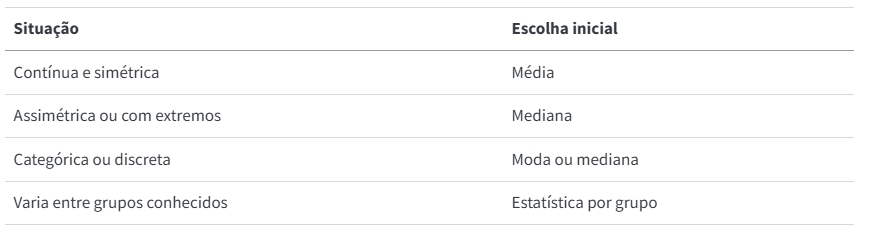

A tabela reúne as escolhas de imputação de acordo com o tipo e a distribuição da variável, conforme o que analisamos acima podemos jutificar as escolhas por alguns fatores.

* **Contínua e simétrica -> média:** em uma distribuição simétrica, média e mediana ficam próximas, e a média aproveita a informação de todos os valores do conjunto.

* **Assimétrica ou com extremos -> mediana:** no aluguel, que tem cauda longa a mediana teve MAE menor que o da média, pois a média foi puxada para cima pelos aluguéis muito altos e superestimou a maioria dos imóveis, se distanciando do valor real dos aluguéis.
* **Categórica ou discreta -> moda ou mediana:** em `furniture`, a média e a mediana não fazem sentido, e a moda (`not furnished`) foi a única opção possível. Em `rooms`, a média gerou um número de quartos impossível, enquanto a mediana e a moda produziram o mesmo valor, sendo ele válido.
* **Varia entre grupos -> estatística por grupo:** a mediana por tier teve o menor erro de todos, pois o aluguel varia muito de um tier para outro.

Essas escolhas precisam se alinhar com o mecanismo de ausência para simular lacunas aleatórias e verificar o desempenho.

**Coluna indicadora.** Antes de imputar, deve-se criar uma coluna que marque quais valores foram estimados, assim, depois da imputação, um valor estimado fica igual a um valor real, e sem essa marcação não seria mais possível separá-los. Entretanto, com a coluna indicadora é possível conferir quantos valores foram preenchidos, verificar se as conclusões mudam quando eles são excluídos e investigar se a ausência está ligada a alguma característica do conjunto de dados.

**E se um grupo não tiver observações?** Na imputação por grupo, se todos os valores de um grupo estiverem ausentes, não há como calcular sua mediana, e o resultado é `NaN`, então quando o grupo tem alguns valores, se ele for muito pequeno, a mediana depende de poucos imóveis e pode mudar bastante de uma amostra para outra e um imóvel poderia definir o valor imputado de todas as lacunas do grupo mesmo sendo distoante da realidade, e por isso, grupos pequenos tendem a gerar estimativas equivocadas.

## 4. Escalonamento: a régua muda, a forma não

### 4.1 Três escaladores

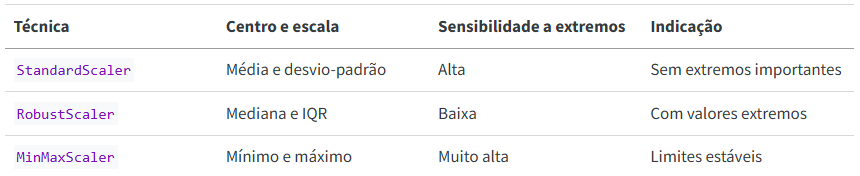

In [55]:
# Aplica os três escaladores ao aluguel
rent_frame = imoveis_true[["rent_amount"]]

scaled = {
    "Original": rent_frame.rent_amount.to_numpy(),
    "StandardScaler": (
        StandardScaler()
        .fit_transform(rent_frame)
        .ravel()
    ),
    "RobustScaler": (
        RobustScaler()
        .fit_transform(rent_frame)
        .ravel()
    ),
    "MinMaxScaler": (
        MinMaxScaler()
        .fit_transform(rent_frame)
        .ravel()
    ),
}

Este bloco aplica três métodos de escalonamento a coluna de aluguel e guarda o resultado de cada um, junto com os valores originais. Ele seguem a mesma ideia de subtrair um valor de referência e dividir por uma medida de dispersão. O que muda entre eles é a escolha desses dois valores:

| Escalador | Fórmula | Resultado |
|---|---|---|
| `StandardScaler` | (x − média) / desvio-padrão | A média vira 0, e cada unidade equivale a um desvio-padrão |
| `RobustScaler` | (x − mediana) / IQR | A mediana vira 0, e cada unidade equivale a um intervalo interquartil |
| `MinMaxScaler` | (x − mínimo) / (máximo − mínimo) | Todos os valores ficam entre 0 e 1 |

Assim, o aluguel deixa de estar em reais e passa a ser expresso em relação à sua própria distribuição, permitindo que as variáveis com unidades diferentes, como quartos, área e aluguel, possam ser comparadas na mesma escala.

A escolha do centro e da escala também define a sensibilidade de cada método a valores extremos, a média, desvio-padrão, mínimo e máximo são afetados pelos aluguéis muito altos (outliers), entretanto a mediana e IQR, não. Esse efeito é analisado na seção 4.2.

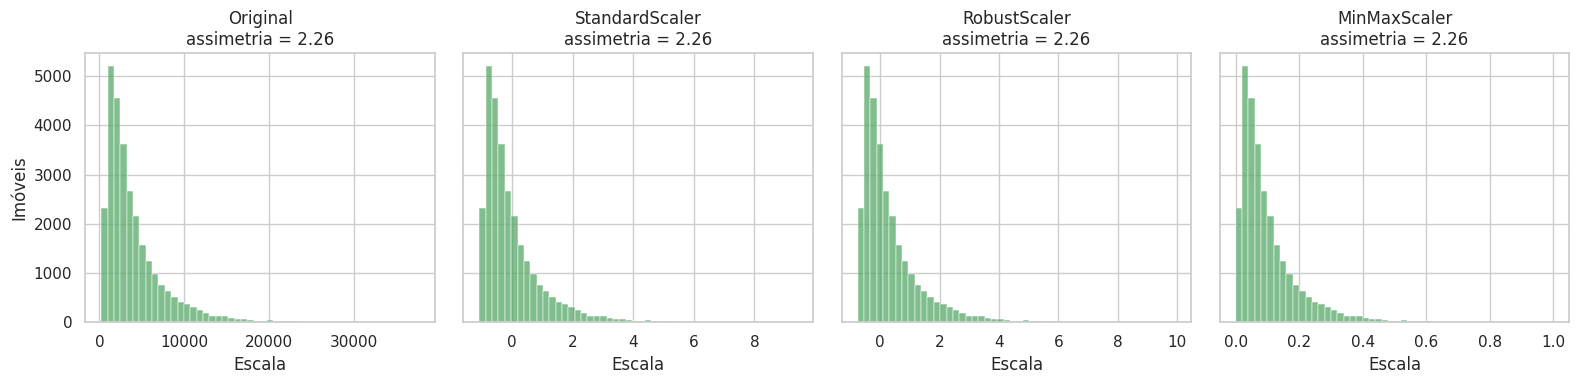

In [56]:
# Histograma do aluguel em cada escala
fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=True)

for ax, (label, values) in zip(axes, scaled.items()):
    sns.histplot(values, bins=50, ax=ax, color="#55A868")
    ax.set(
        title=f"{label}\nassimetria = {stats.skew(values):.2f}",
        xlabel="Escala",
        ylabel="Imóveis",
    )

plt.tight_layout()
plt.show()

O código cria quatro gráficos, um para cada versão do aluguel, e calcula a assimetria de cada, podemos notar que os quatro histogramas tem exatamente o mesmo formato com pico a esquerda e a mesma cauda longa a direita. A diferença entre os gráficos está na escala que são representados.

* **Original:** os valores continuam em reais
* **StandardScaler:** o zero passa a ser a média, e os valores indicam quantos desvios-padrão cada aluguel está acima ou abaixo dela.
* **RobustScaler:** o zero passa a ser a mediana, e os valores indicam quantos intervalos interquartis cada aluguel está acima ou abaixo dela
* **MinMaxScaler:** os valores ficam entre 0 e 1, mas a maioria se concentra perto de 0, pois o máximo, usado como referência, é um aluguel muito alto.

Devido o escalonamento apenas subtrair um valor e divide por outro, aplicando a mesma operação a todos os imóveis a ordem dos imóveis e as proporções entre as distâncias continuam iguais.

### 4.2 Sensibilidade a extremos

In [57]:
# Min-Max ajustado com um aluguel fictício de R$ 500 mil
with_extreme = pd.concat(
    [rent_frame, pd.DataFrame({"rent_amount": [500_000.]})],
    ignore_index=True,
)

minmax_extreme = (
    MinMaxScaler()
    .fit_transform(with_extreme)
    .ravel()[:-1]
)

Este bloco testa a sensibilidade do MinMaxScaler a valores extremos e mostra que um único valor, entre quase 30 mil imóveis, é capaz de mudar a escala de todos os outros, esse problema pode acontecer com dados reais sempre que houver um valor extremo ou um erro de digitação.

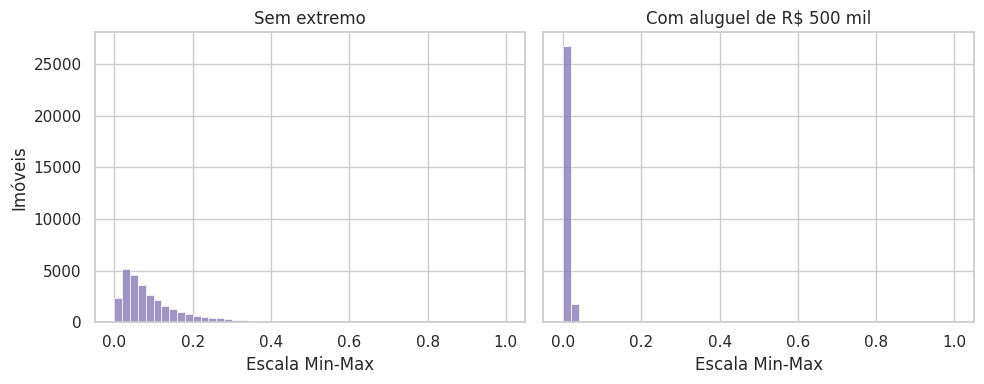

In [58]:
# Min-Max sem e com o valor extremo
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)

for ax, values, title in zip(
    axes,
    [scaled["MinMaxScaler"], minmax_extreme],
    ["Sem extremo", "Com aluguel de R$ 500 mil"],
):
    sns.histplot(
        values,
        bins=50,
        binrange=(0, 1),
        ax=ax,
        color="#8172B2",
    )
    ax.set(
        title=title,
        xlabel="Escala Min-Max",
        ylabel="Imóveis",
    )

plt.tight_layout()
plt.show()

Os histogramas possuem o mesmo intervalo, toda a diferença visual do gráfico é causada pelo valor extremo de R$ 500 mil, pois com esse valor todos os imóveis ficam concentrados na primeira barra e poucos ficam nas barras seguintes, que são os imóveis de maior valor.

Com isso o imóvel que se destaca é o imóvel ficticio de 500 mil, enquanto os imóveis reais tem valor próximos entre si mas extremamentes distantes de 500 mil passam despercebidos pelo algoritmo.

## 5. Transformações: a forma muda

### 5.1 Aluguel positivo: log e Box-Cox

In [59]:
# Aluguel original, em log e em Box-Cox
rent = imoveis_true.rent_amount

boxcox_rent, boxcox_lambda = stats.boxcox(rent)

rent_transformed = {
    "Original": rent,
    "log": np.log(rent),
    f"Box-Cox (λ={boxcox_lambda:.2f})": boxcox_rent,
}

As transformações são responsáveis por mudar a forma da distribuição, reduzindo a cauda longa do aluguel, para isso, utiliza o `np.log` para aplicar o logaritmo a cada aluguel, fazendo com que as distâncias entre os valores passem a representar proporções, diminuindo a distância dos aluguéis altos em relação aos demais. Também é utilizado o `stats.boxcox`, que vai estimar um lambda a partir do conjunto de dados para transformar a distribuição e deixá-la o mais próximo possível da distribuição normal.

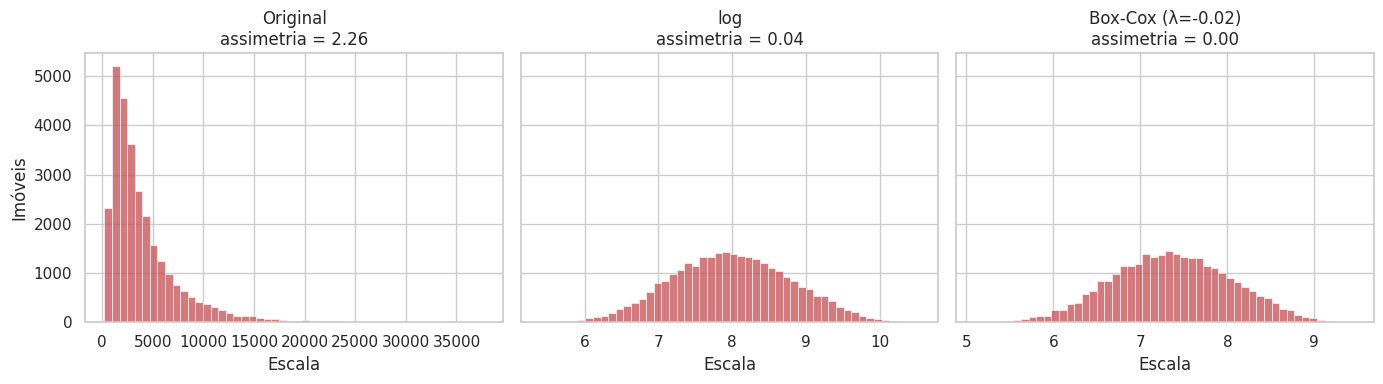

In [60]:
# Histogramas das transformações do aluguel
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)

for ax, (label, values) in zip(axes, rent_transformed.items()):
    sns.histplot(values, bins=50, ax=ax, color="#C44E52")
    ax.set(
        title=f"{label}\nassimetria = {stats.skew(values):.2f}",
        xlabel="Escala",
        ylabel="Imóveis",
    )

plt.tight_layout()
plt.show()

O bloco gera três histogramas mantendo o mesmo eixo vertical para facilitar a comparação, um loop itera sobre as variáveis transformadas, plotando os gráficos e inserindo no título o cálculo da assimetria em tempo real usando stats.

O primeiro gráfico mostra os dados originais com uma forte assimetria positiva devido a poucos aluguéis muito caros, as transformações comprimiram esses valores extremos, deixando a distribuição mais simétrica. Os gráficos de Log e Box-Cox ficaram quase idênticos porque o lambda estimado foi próximo de 0, situação em que age matematicamente como um logaritmo natural.

### 5.2 Distância com zeros: log1p e Yeo-Johnson

In [61]:
# Distância original, em log1p e em Yeo-Johnson
transit = imoveis_true.transit_distance_min

pt = PowerTransformer(method="yeo-johnson", standardize=False)

transit_yj = (
    pt
    .fit_transform(imoveis_true[["transit_distance_min"]])
    .ravel()
)

transformed = {
    "Original": transit,
    "log1p": np.log1p(transit),
    f"Yeo-Johnson (λ={pt.lambdas_[0]:.2f})": transit_yj,
}

O código trata a variável de distância ao transporte, que possui valores iguais a zero. Como o logaritmo comum e o Box-Cox não aceitam zeros, o código aplica duas alternativas, o np.log1p, que soma 1 ao valor antes de tirar o log e o PowerTransformer configurado com o método yeo-johnson, guardando as versões em um dicionário para comparação.

O log1p resolve o problema matemático do zero de forma simples, mas acaba comprimindo a cauda direita da distribuição além do necessário, então, o método de Yeo-Johnson se mostra uma opção mais adequada aqui, pois ele calcula um lambda para os dados aplicando uma transformação mais suave que reduz a assimetria sem distorcer tanto a forma final da distribuição.

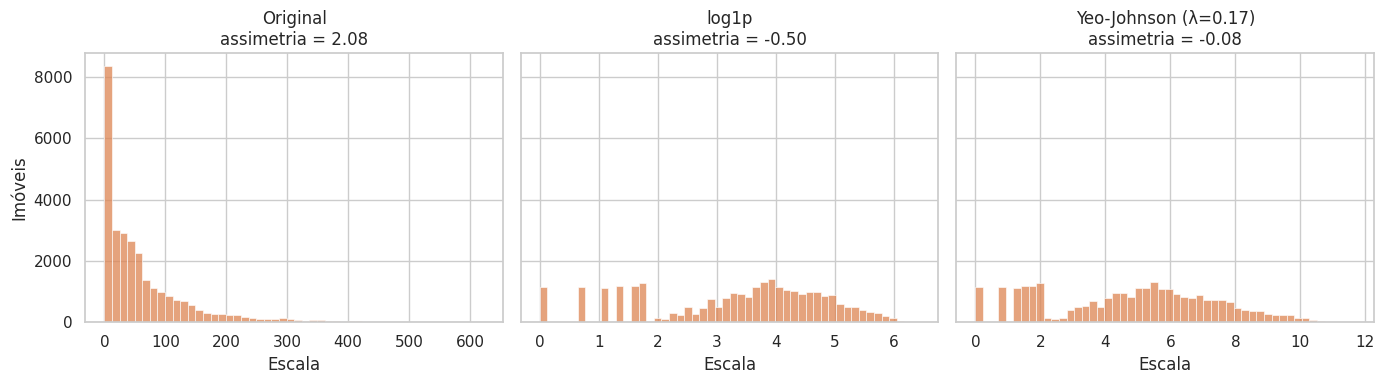

In [62]:
# Histogramas das transformações da distância
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)

for ax, (label, values) in zip(axes, transformed.items()):
    sns.histplot(values, bins=50, ax=ax, color="#DD8452")
    ax.set(
        title=f"{label}\nassimetria = {stats.skew(values):.2f}",
        xlabel="Escala",
        ylabel="Imóveis",
    )

plt.tight_layout()
plt.show()

O gráfico original revela uma forte assimetria positiva 2.08, entretando, aplicando o log1p, a assimetria inverteu para o lado negativo -0.50, ou seja, a transformação comprimiu a cauda direita mais que o necessário, por ultimo o método de Yeo-Johnson obteve o melhor desempenho, ele aplicou uma transformação mais suave que reduziu a assimetria para quase zero -0.08, deixando a distribuição mais equilibrada e simétrica.

### 5.3 Resumo das transformações

* log e Box-Cox: Funcionam se os seus dados forem positivos maiores que zero. O log leva vantagem por ser muito mais fácil de interpretar e explicar para o negócio.

* log1p: É uma boa alternativa para quando a sua variável possui zeros, pois ele resolve o problema matemático e mantém a facilidade de interpretação.

* Yeo-Johnson: Aceita números positivos, negativos e zero, entretanto, tem como desvantagem que o valor transformado fica bem mais difícil de ser interpretado na escala original.


## 6. Aplicação e comparação final

### 6.1 Registrar as lacunas

In [63]:
# Colunas indicadoras das lacunas originais
imoveis_processed = (
    imoveis
    .assign(
        hoa_missing=lambda x: x.hoa.isna(),
        parking_spaces_missing=lambda x: x.parking_spaces.isna(),
    )
)

O código cria duas novas colunas (hoa_missing e parking_spaces_missing), para que elas funcionem como marcadores booleanos, indicando exatamente quais linhas possuíam dados vazios nas colunas de condomínio e vagas.

Esse passo deve ser feito antes da imputação, pois se preenchermos as lacunas diretamente, a informação de quais dados eram originais se perde, logo, criar essas colunas indicadoras permite que a gente saiba quais valores são reais e quais foram apenas estimados.

### 6.2 Imputar pela mediana do grupo

In [64]:
# Imputa hoa e vagas pela mediana de cada grupo
groups = ["property_type", "tier"]

imoveis_processed = (
    imoveis_processed
    .assign(
        hoa=lambda x: (
            x
            .groupby(groups)
            .hoa
            .transform(lambda s: s.fillna(s.median()))
            .fillna(imoveis.hoa.median())
        ),
        parking_spaces=lambda x: (
            x
            .groupby(groups)
            .parking_spaces
            .transform(lambda s: s.fillna(s.median()))
            .fillna(imoveis.parking_spaces.median())
        ),
    )
)

O bloco preenche as lacunas de condomínio `hoa` e vagas `parking_spaces` utilizando a mediana de categorias específicas. Os dados são divididos pelo tipo de imóvel e padrão `tier`, após isso, é substituido os valores ausentes pela mediana daquele grupo em específico, se algum grupo não tiver nenhum dado para calcular a mediana, ele preenche a lacuna restante usando a mediana global.

Imputar dados agrupando por características semelhantes melhora a precisão da estimativa evitando distorções, como aplicar o valor de condomínio de um apartamento de luxo a um imóvel popular.

In [65]:
# Lacunas restantes e valores estimados
(
    imoveis_processed
    .agg(
        {
            "hoa": lambda s: s.isna().sum(),
            "parking_spaces": lambda s: s.isna().sum(),
            "hoa_missing": "sum",
            "parking_spaces_missing": "sum",
        }
    )
)

,0
hoa,0
parking_spaces,0
hoa_missing,505
parking_spaces_missing,297


O bloco realiza uma checagem na base de dados e  calcula quantos valores vazios ainda existem nas colunas de condomínio e vagas, e ao mesmo tempo soma as colunas indicadoras para totalizar os registros.

O esperado é que a contagem de vazios nas colunas originais retorne zero, confirmando que o preenchimento funcionou e nenhuma lacuna ficou para trás. Já a soma das colunas indicadoras serve para mostrar a quantidade exata de valores que foram artificialmente estimados e introduzidos nos dados.

### 6.3 Reduzir as caudas

In [66]:
# Log nas variáveis positivas e Yeo-Johnson na distância
imoveis_processed = (
    imoveis_processed
    .assign(
        area=lambda x: np.log(x.area),
        rent_amount=lambda x: np.log(x.rent_amount),
        property_tax=lambda x: np.log(x.property_tax),
        total=lambda x: np.log(x.total),
        transit_distance_min=lambda x: stats.yeojohnson(
            x.transit_distance_min
        )[0],
    )
)

O bloco aplica as transformações matemáticas na base de dados, usando o logaritmo natural nas variáveis financeiras e de área e a transformação de Yeo-Johnson na variável de distância.

Essa etapa consolida a mudança de forma das distribuições de todas as variáveis contínuas de uma só vez, reduzindo a redução de assimetrias, padronizando os dados e mais robustos contra os outiliers.

### 6.4 Antes e depois

In [67]:
# Variáveis comparadas e seus rótulos nos gráficos
columns = [
    "area",
    "rent_amount",
    "property_tax",
    "total",
    "transit_distance_min",
]

labels = ["Área", "Aluguel", "IPTU", "Total", "Distância"]

O código define duas listas, columns armazena os nomes exatos das variáveis da base de dados, enquanto labels guarda os nomes amigáveis que serão exibidos visualmente.

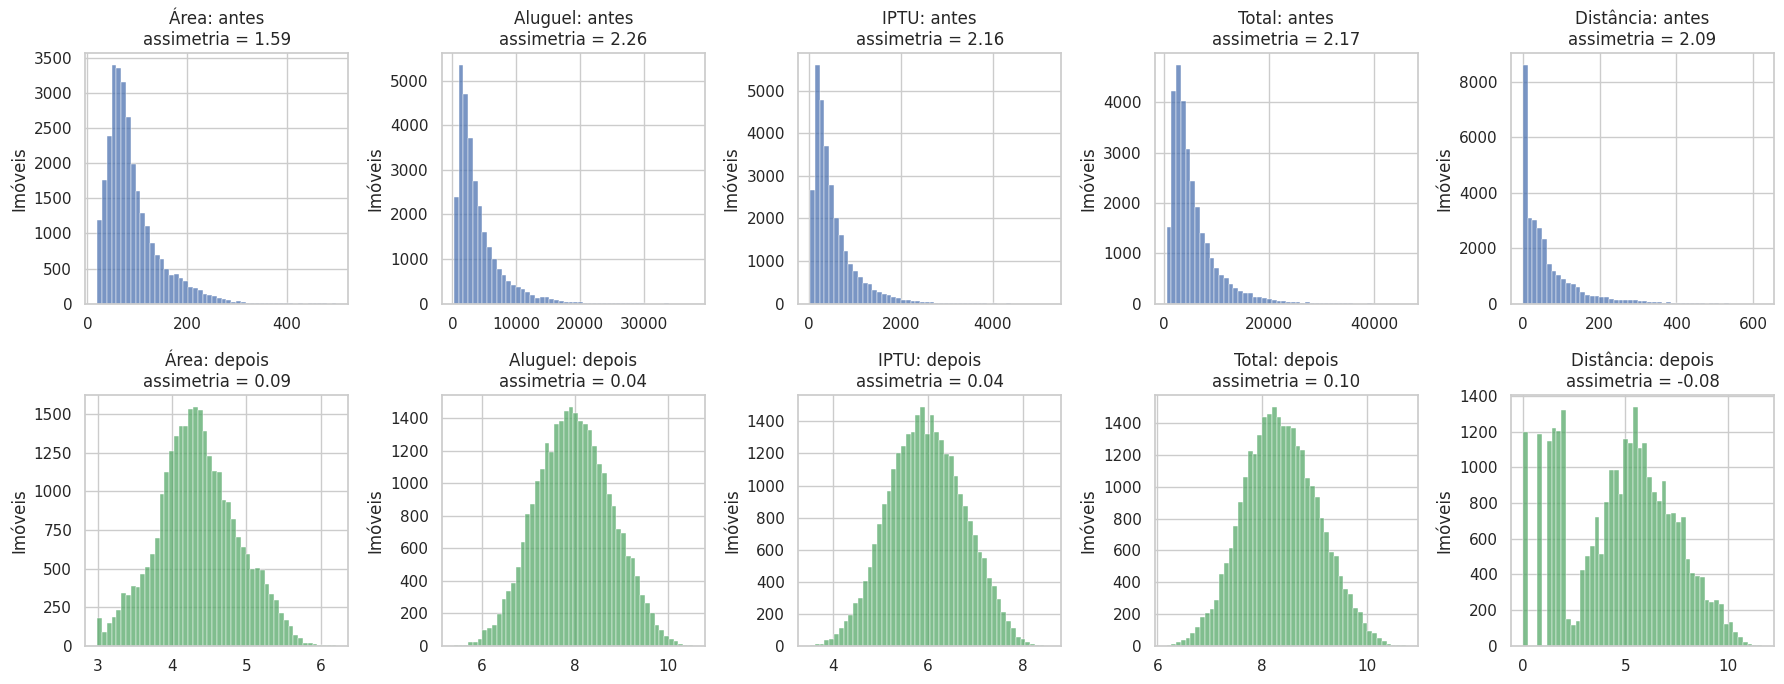

In [68]:
# Distribuições antes (linha de cima) e depois (linha de baixo)
fig, axes = plt.subplots(2, 5, figsize=(18, 7))

for col, label, ax1, ax2 in zip(columns, labels, axes[0], axes[1]):
    before, after = imoveis[col], imoveis_processed[col]
    sns.histplot(before, bins=50, ax=ax1, color="#4C72B0")
    ax1.set(
        title=f"{label}: antes\nassimetria = {stats.skew(before):.2f}",
        xlabel="",
        ylabel="Imóveis",
    )
    sns.histplot(after, bins=50, ax=ax2, color="#55A868")
    ax2.set(
        title=f"{label}: depois\nassimetria = {stats.skew(after):.2f}",
        xlabel="",
        ylabel="Imóveis",
    )

plt.tight_layout()
plt.show()

O código cria os gráficos para comparar o antes e o depois das variáveis, o laço de repetição percorre as colunas e os eixos, plotando os dados originais na linha superior e os dados já processados na linha inferior.

O painel consolida o impacto do pré-processamento, na linha superior todas as variáveis originais sofrem com forte assimetria positiva, onde poucos valores muito altos esticam os eixos, entretanto, na linha inferior o efeito do logaritmo e do yeo-johnson as distâncias dos valores extremos foram comprimidas. Com a assimetria reduzida as distribuições assumiram um formato de mais equilibrado e simétrico.

## 7. Guia rápido

* Ausência estrutural: Ocorre quando o dado falta por definição da própria observação, onde a regra é não preencher, mas sim registrar o motivo para criar um indicador específico.

* Contínua simétrica: Para variáveis numéricas sem valores atípicos, preenche-se as lacunas utilizando a média, que vai aproveitar toda a magnitude dos dados.

* Assimétrica ou com extremos: Quando a variável tem outliers ou cauda longa que distorce a média, então utiliza-se a mediana para a imputação, pois ela ignora os extremos.

* Categórica ou discreta: Para textos como o exemplo mobiliado/não mobiliado ou contagens, preenche-se com a moda ou a Mediana, evitando a criação de médias quebradas sem sentido no mundo real.

* Varia entre grupos: Quando o valor esperado muda conforme o perfil como o exemplo do preço de condomínio por bairro, preenche-se a lacuna usando a mediana por grupo, de modo que contextualize a estimativa.

* Escalas diferentes, sem extremos: Para padronizar a régua das variáveis usando o Z-score, ele vai focar na média e no desvio-padrão, sendo ideal apenas quando não há extremos importantes.

* Escalas diferentes, com extremos: Padronização segura contra outliers usando o RobustScaler, pois ele baseia o cálculo na mediana e no intervalo interquartil `IQR`, evitando que um valor gigante esmague os dados comuns.

* Limites estáveis: Quando se conhece o piso e o teto da variável, usa-se o Min-Max para manter os valores em uma escala de 0 a 1, isso exige cuidado, pois outliers podem quebra a escala.

* Cauda positiva: Para reduzir a assimetria de variáveis maiores que zero, aplica-se Log ou Box-Cox para comprimir as distâncias e mudar a forma da distribuição.

* Cauda com zeros: Quando a variável possui o valor zero no meio dos dados o logaritmo falha matematicamente, então, usa-se o log1p ou o Yeo-Johnson para obter a mesma correção de forma.

## Perguntas para consolidar

**Imputar sempre melhora a análise?**  
Não necessariamente, pois um erro médio `MAE` baixo em um experimento controlado não garante sucesso na base real se o mecanismo de ausência dos dados for diferente do simulado. Se os dados reais faltam por um motivo específico a imputação pode inserir valores distorcidos, reduzir a variabilidade da base e esconder tendências reais, prejudicando as conclusões.

**Por que o StandardScaler não resolveu a assimetria?**  
Porque o escalonamento realiza apenas uma transformação subtraindo o centro e dividindo pela escala, essa operação muda apenas a unidade de medida. Como todas as distâncias são multiplicadas por uma mesma constante a ordenação dos dados é mantida e a assimetria e o formato do histograma continuam exatamente os mesmos.

**Qual escala você apresentaria ao gestor?**
Para um gestor que precisa ter as ideias rápidas e práticas pro negócio o ideal é exibir os resultados na escala original, sendo a escala utilizada por ele nas decisões, guardando as informações técnicas, valores com logs apenas na modelagem.

## Para casa

In [69]:
# Calculando o MAE da média e da mediana para a variável rooms
rooms_true = imoveis_true["rooms"]
rng_local = np.random.default_rng(123)

def erase_fixed(values, share):
    return values.mask(rng_local.random(len(values)) < share)

rooms_missing = erase_fixed(rooms_true, 0.10)

mean_val = rooms_missing.mean()
median_val = rooms_missing.median()

missing_idx = rooms_missing.isna()
true_vals = rooms_true[missing_idx]

mae_mean = (true_vals - mean_val).abs().mean()
mae_median = (true_vals - median_val).abs().mean()

print(f"MAE Média: {mae_mean:.4f} | MAE Mediana: {mae_median:.4f}")

MAE Média: 1.0148 | MAE Mediana: 0.9623


Como o número de quartos `rooms` é uma variável quantitativa discreta e geralmente apresenta assimetria, a mediana costuma apresentar um `MAE` menor ou mais coerente, já a média produz valores quebrados o que é impossível no mundo real para um imóvel, fazendo com que a mediana erre menos.

In [70]:
# Imputando o aluguel combinando tier e zona como grupos
imoveis_processado = imoveis_missing.assign(
    rent_tier_zona=lambda x: x.groupby(["tier", "zona"])["rent_amount"]
    .transform(lambda s: s.fillna(s.median()))
    .fillna(imoveis_missing.rent_amount.median()),

    rent_bairro=lambda x: x.groupby("bairro")["rent_amount"]
    .transform(lambda s: s.fillna(s.median()))
    .fillna(imoveis_missing.rent_amount.median())
)

display(
    imoveis_processado[["bairro", "tier", "zona", "rent_amount", "rent_tier_zona", "rent_bairro"]]
    .head(10)
)

,bairro,tier,zona,rent_amount,rent_tier_zona,rent_bairro
0,Vila Mariana,premium,Zona Sul,5060.0,5060.0,5060.0
1,Ipiranga,mid,Zona Sul,2470.0,2470.0,2470.0
2,Raposo Tavares,mid,Zona Oeste,6270.0,6270.0,6270.0
3,Brooklin,luxury,Zona Sul,NaN,7710.0,6880.0
4,Itaquera,affordable,Zona Leste,1370.0,1370.0,1370.0
5,Brooklin,luxury,Zona Sul,3260.0,3260.0,3260.0
6,Brooklin,luxury,Zona Sul,6080.0,6080.0,6080.0
7,Limão,mid,Zona Norte,1320.0,1320.0,1320.0
8,Jardim Europa,luxury,Zona Oeste,7570.0,7570.0,7570.0
9,Guaianases,affordable,Zona Leste,750.0,750.0,750.0


O bloco aplica duas imputações na mesma base, a coluna `rent_tier_zona` estima os valores vazios cruzando o `tier` e a `zona`, já a coluna `rent_bairro` foca no bairro.

Quando agrupamos por `tier` e `zona`, são criadas categorias amplas que conseguem obter um bom volume de dados, ou seja, possuem medianas mais estáveis e confiáveis, entretanto, quando se utiliza o bairro, a base de dados é quebrada em mais subconjuntos com menos objetos. O problema desses grupos pequenos é que existem bairros que possuem pouquíssimos ou nenhum registro, então é gerado subgrupos vazios ou instáveis, logo, a mediana será puxada por casos isolados aumentando o erro de imputação.

In [71]:
# Filtrando apenas apartamentos e calculando as transformações para hoa
aparts = imoveis_true.query("property_type == 'apartamento'")["hoa"].dropna()

log1p_hoa = np.log1p(aparts)
boxcox_hoa, _ = stats.boxcox(aparts + 1)
yj_pt = PowerTransformer(method="yeo-johnson", standardize=False)
yj_hoa = yj_pt.fit_transform(aparts.to_frame()).ravel()

tabela_assimetria = pd.DataFrame({
    "Transformação": ["Original (Sem Transformação)", "log1p", "Box-Cox", "Yeo-Johnson"],
    "Assimetria (Skew)": [
        stats.skew(aparts),
        stats.skew(log1p_hoa),
        stats.skew(boxcox_hoa),
        stats.skew(yj_hoa)
    ]
})

display(tabela_assimetria)

,Transformação,Assimetria (Skew)
0,Original (Sem Transformação),2.131779
1,log1p,0.150074
2,Box-Cox,0.000474
3,Yeo-Johnson,0.000474


O Box-Cox e o Yeo-Johnson apresentam os menores valores de assimetria pois calculam um $\lambda$ otimizado para a distribuição, no entanto, mesmo que sejam ótimos para os algoritmos, não devem ser apresentado ao gestor, pois alteram a unidade original de medida, deve ser mostrado na escala.